<a href="https://colab.research.google.com/github/OlegSamarsky/MN/blob/main/%D0%A2%D0%B5%D1%81%D1%82%D0%BE%D0%B2%D0%B5_%D0%97%D0%B0%D0%B2%D0%B4_%D0%A1%D0%B0%D0%BC%D0%B0%D1%80%D1%81%D1%8C%D0%BA%D0%B8%D0%B9_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Завантаження бібліотек та датасету

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

sns.set_style("whitegrid")

link_1 = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
link_2 = "https://raw.githubusercontent.com/blastchar/telco-customer-churn/master/WA_Fn-UseC_-Telco-Customer-Churn.csv"

try:
    churn_df = pd.read_csv(link_1)
except Exception:
    churn_df = pd.read_csv(link_2)

print(f"Рядків: {churn_df.shape[0]}, стовпців: {churn_df.shape[1]}")
churn_df.head()

Рядків: 7043, стовпців: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


2. Аналіз даних

In [2]:
# Перевірка типів даних, дублікатів та прихованих пропусків
print("Кількість дублікатів:", churn_df.duplicated().sum())

churn_df['TotalCharges'] = pd.to_numeric(churn_df['TotalCharges'], errors='coerce')
print("\nПропуски по стовпцях:")
print(churn_df.isnull().sum()[churn_df.isnull().sum() > 0])

print("\nСтатистика числових колонок:")
display(churn_df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].describe().round(2))

print("\nСпіввідношення класів Churn:")
print(churn_df['Churn'].value_counts())

Кількість дублікатів: 0

Пропуски по стовпцях:
TotalCharges    11
dtype: int64

Статистика числових колонок:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00,7032.00
mean,0.16,32.37,64.76,2283.30
std,0.37,24.56,30.09,2266.77
min,0.00,0.00,18.25,18.80
25%,0.00,9.00,35.50,401.45
50%,0.00,29.00,70.35,1397.48
75%,0.00,55.00,89.85,3794.74
max,1.00,72.00,118.75,8684.80



Співвідношення класів Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


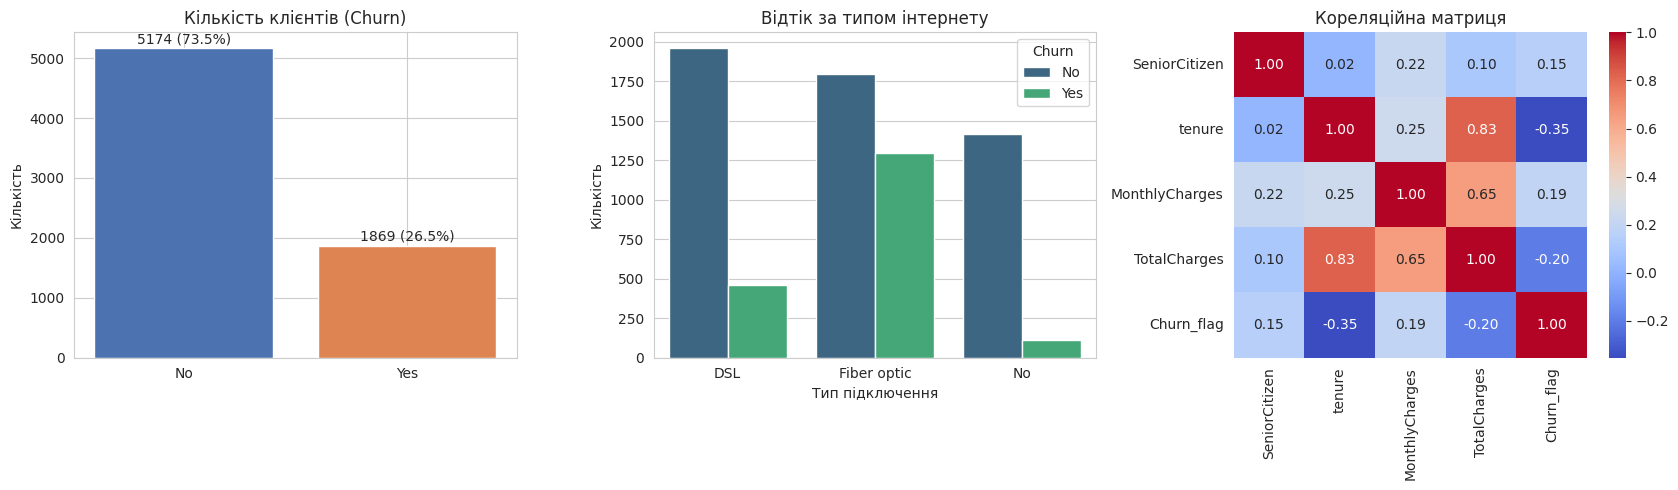

In [3]:
# Графічний аналіз факторів відтоку
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Кількість клієнтів за класами
churn_counts = churn_df['Churn'].value_counts()
axes[0].bar(churn_counts.index, churn_counts.values, color=['#4c72b0', '#dd8452'])
axes[0].set_title('Кількість клієнтів (Churn)')
axes[0].set_ylabel('Кількість')
for idx, val in enumerate(churn_counts.values):
    axes[0].text(idx, val + 80, f"{val} ({val / len(churn_df) * 100:.1f}%)", ha='center')

# 2. Відтік залежно від типу інтернету
sns.countplot(data=churn_df, x='InternetService', hue='Churn', palette='viridis', ax=axes[1])
axes[1].set_title('Відтік за типом інтернету')
axes[1].set_xlabel('Тип підключення')
axes[1].set_ylabel('Кількість')

# 3. Кореляція числових ознак із відтоком
corr_data = churn_df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].copy()
corr_data['Churn_flag'] = (churn_df['Churn'] == 'Yes').astype(int)
sns.heatmap(corr_data.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[2])
axes[2].set_title('Кореляційна матриця')

plt.tight_layout()
plt.show()

3. Підготовка даних

In [4]:
# Видаляємо 11 рядків із порожнім TotalCharges та службовий ID
clean_df = churn_df.dropna(subset=['TotalCharges']).drop(columns=['customerID']).reset_index(drop=True)

# Цільова змінна (1 - клієнт пішов, 0 - залишився)
target = (clean_df['Churn'] == 'Yes').astype(int)

# Перетворення категоріальних колонок у числові фіктивні змінні
features = pd.get_dummies(clean_df.drop(columns=['Churn']), drop_first=True, dtype=int)

# Поділ на навчальну (75%) та тестову (25%) вибірки
X_tr, X_te, y_tr, y_te = train_test_split(
    features, target, test_size=0.25, random_state=17, stratify=target
)

# Нормалізація числових ознак у діапазон [0, 1]
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = MinMaxScaler()

X_tr = X_tr.copy()
X_te = X_te.copy()
X_tr[num_cols] = scaler.fit_transform(X_tr[num_cols])
X_te[num_cols] = scaler.transform(X_te[num_cols])

print(f"Навчальна вибірка: {X_tr.shape}")
print(f"Тестова вибірка: {X_te.shape}")

Навчальна вибірка: (5274, 30)
Тестова вибірка: (1758, 30)


4. Реалізація та порівняння моделей

Результати базових моделей на тестовому наборі:


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,AdaBoost,0.8055,0.6559,0.5632,0.6060,0.8508
1,HistGradientBoosting,0.7975,0.6300,0.5760,0.6018,0.8349
2,Decision Tree,0.7912,0.6232,0.5418,0.5796,0.8254
3,KNN (k=7),0.7543,0.5390,0.5182,0.5284,0.7858


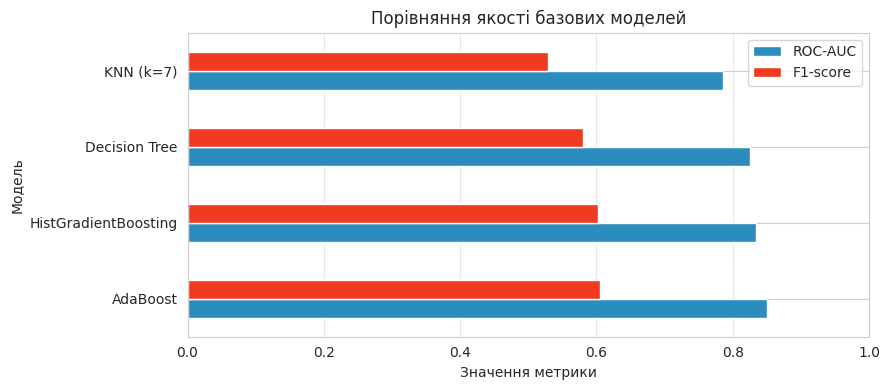

In [5]:
classifiers = {
    'KNN (k=7)': KNeighborsClassifier(n_neighbors=7),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=17),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=17),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=17)
}

metrics_list = []
fitted_models = {}

for model_name, model in classifiers.items():
    model.fit(X_tr, y_tr)
    fitted_models[model_name] = model

    preds = model.predict(X_te)
    probs = model.predict_proba(X_te)[:, 1]

    metrics_list.append({
        'Модель': model_name,
        'Accuracy': accuracy_score(y_te, preds),
        'Precision': precision_score(y_te, preds),
        'Recall': recall_score(y_te, preds),
        'F1-score': f1_score(y_te, preds),
        'ROC-AUC': roc_auc_score(y_te, probs)
    })

summary_table = pd.DataFrame(metrics_list).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)
print("Результати базових моделей на тестовому наборі:")
display(summary_table.round(4))

# Візуальне порівняння ROC-AUC та F1-score
summary_table.set_index('Модель')[['ROC-AUC', 'F1-score']].plot(
    kind='barh', figsize=(9, 4), color=['#2b8cbe', '#f03b20']
)
plt.title('Порівняння якості базових моделей')
plt.xlabel('Значення метрики')
plt.xlim(0, 1)
plt.grid(axis='x', alpha=0.4)
plt.tight_layout()
plt.show()

5. Підбір параметрів та вибір найкращої моделі

Найкращі знайдені параметри: {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.03}
ROC-AUC на крос-валідації: 0.8460
Тестовий Accuracy: 0.7998
Тестовий F1-score: 0.6036
Тестовий ROC-AUC:  0.8467

Звіт класифікації найкращої моделі:
                precision    recall  f1-score   support

Залишиться (0)       0.85      0.88      0.87      1291
      Піде (1)       0.64      0.57      0.60       467

      accuracy                           0.80      1758
     macro avg       0.74      0.73      0.73      1758
  weighted avg       0.79      0.80      0.80      1758



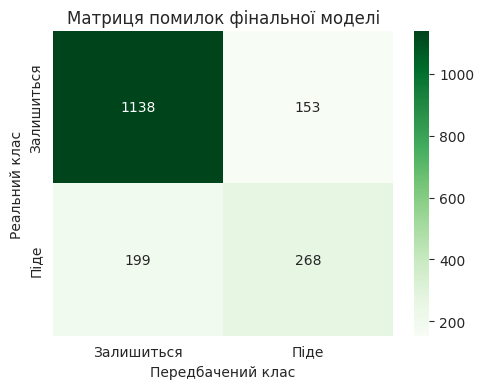

In [6]:
# Підбір гіперпараметрів для HistGradientBoosting через RandomizedSearchCV
param_dist = {
    'learning_rate': [0.03, 0.05, 0.08, 0.1],
    'max_iter': [80, 120, 160, 200],
    'max_leaf_nodes': [15, 25, 31],
    'min_samples_leaf': [20, 35, 50]
}

random_search = RandomizedSearchCV(
    estimator=HistGradientBoostingClassifier(random_state=17),
    param_distributions=param_dist,
    n_iter=12,
    cv=4,
    scoring='roc_auc',
    random_state=17,
    n_jobs=-1
)
random_search.fit(X_tr, y_tr)

final_model = random_search.best_estimator_
final_preds = final_model.predict(X_te)
final_probs = final_model.predict_proba(X_te)[:, 1]

print("Найкращі знайдені параметри:", random_search.best_params_)
print(f"ROC-AUC на крос-валідації: {random_search.best_score_:.4f}")
print(f"Тестовий Accuracy: {accuracy_score(y_te, final_preds):.4f}")
print(f"Тестовий F1-score: {f1_score(y_te, final_preds):.4f}")
print(f"Тестовий ROC-AUC:  {roc_auc_score(y_te, final_probs):.4f}")

print("\nЗвіт класифікації найкращої моделі:")
print(classification_report(y_te, final_preds, target_names=['Залишиться (0)', 'Піде (1)']))

# Матриця помилок
plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_te, final_preds),
    annot=True, fmt='d', cmap='Greens',
    xticklabels=['Залишиться', 'Піде'],
    yticklabels=['Залишиться', 'Піде']
)
plt.title('Матриця помилок фінальної моделі')
plt.xlabel('Передбачений клас')
plt.ylabel('Реальний клас')
plt.tight_layout()
plt.show()

6. Прогноз для конкретного клієнта

In [7]:
def check_customer(customer_info: dict):
    raw_row = pd.DataFrame([customer_info])
    encoded_row = pd.get_dummies(raw_row, dtype=int)
    # Вирівнюємо набір стовпців під навчальну матрицю
    aligned_row = encoded_row.reindex(columns=X_tr.columns, fill_value=0)
    aligned_row[num_cols] = scaler.transform(aligned_row[num_cols])

    pred_class = final_model.predict(aligned_row)[0]
    leave_prob = final_model.predict_proba(aligned_row)[0][1]

    verdict = "КЛІЄНТ ПІДЕ" if pred_class == 1 else "КЛІЄНТ ЗАЛИШИТЬСЯ"
    print("-" * 45)
    print(f"Прогноз: {verdict}")
    print(f"Ймовірність відтоку: {leave_prob * 100:.2f}%")
    print(f"Ймовірність залишитися: {(1 - leave_prob) * 100:.2f}%")
    print("-" * 45)

# Дані клієнта для перевірки (можна змінити будь-яке поле)
sample_customer = {
    'gender': 'Male',
    'SeniorCitizen': 0,
    'Partner': 'Yes',
    'Dependents': 'Yes',
    'tenure': 36,
    'PhoneService': 'Yes',
    'MultipleLines': 'Yes',
    'InternetService': 'DSL',
    'OnlineSecurity': 'Yes',
    'OnlineBackup': 'Yes',
    'DeviceProtection': 'No',
    'TechSupport': 'Yes',
    'StreamingTV': 'No',
    'StreamingMovies': 'No',
    'Contract': 'One year',
    'PaperlessBilling': 'No',
    'PaymentMethod': 'Credit card (automatic)',
    'MonthlyCharges': 64.50,
    'TotalCharges': 2322.00
}

check_customer(sample_customer)

---------------------------------------------
Прогноз: КЛІЄНТ ЗАЛИШИТЬСЯ
Ймовірність відтоку: 5.03%
Ймовірність залишитися: 94.97%
---------------------------------------------


##7. Висновки

Для роботи я взяв датасет на 7043 клієнти, де під час перевірки видалив 11 рядків із пропусками в TotalCharges і побачив, що 73,5% користувачів залишаються, а 26,5% йдуть. Далі я прибрав непотрібний ID клієнта, перевів текстові категорії в числа, поділив вибірку у пропорції 75 на 25 та нормалізував числові стовпці. Серед чотирьох протестованих моделей найкраще спрацювали бустингові алгоритми AdaBoost та HistGradientBoosting, випередивши дерево рішень і KNN. Після підбору параметрів через RandomizedSearchCV фінальна модель HistGradientBoosting показала точність майже 80% і покращила ROC-AUC на тесті з 0,8349 до 0,8467. Наприкінці я перевірив модель на прикладі конкретного клієнта з річним контрактом і отримав прогноз, що він залишиться з імовірністю 94,97%.